# 05 · Placar e análise: C0, C1 e C2

Fase 8 do plano. O placar oficial é o do **test** (36 perguntas, medidas uma única vez); o dev
aparece à parte.

**As três configurações**, todas com o mesmo LLM local (qwen3 4B instruct, Ollama):
- **C0:** o LLM sozinho, sem a base de normas;
- **C1:** busca nas normas com portão de recusa e geração com citação verificável;
- **C2:** o C1 com um agente que também consulta a agenda de paradas programadas.

**Duas fontes de métrica:**
- **automática:** fatos-chave, citação e números, calculada pelo código;
- **manual:** a conferência do Pedro nas respostas do test (`avaliacao/revisao/conferencia_test.yaml`).

A acurácia e a alucinação **oficiais são as manuais**. Todos os números trazem a contagem e o IC
de Wilson de 95%, porque as amostras são pequenas.

In [1]:
import json
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import pandas as pd
import yaml

from src.avaliacao.casos import carregar_congelado
from src.avaliacao.recuperacao import RESPONDIVEIS

A = RAIZ / "avaliacao"
G = A / "runs" / "geracao"
Q = "qwen3_4b-instruct-2507-q4_K_M"
placar = pd.read_csv(A / "placar.csv")
conf = yaml.safe_load((A / "revisao" / "conferencia_test.yaml").read_text(encoding="utf-8"))["itens"]
erros = yaml.safe_load((A / "revisao" / "erros_test.yaml").read_text(encoding="utf-8"))["falhas"]
casos = {c.id: c for c in carregar_congelado("test")}
pd.set_option("display.max_colwidth", 160)


def run(nome):
    with open(G / f"{nome}.jsonl", encoding="utf-8") as f:
        return {(x := json.loads(l))["id"]: x for l in f if l.strip()}


def celula(r):
    if pd.isna(r["k"]):
        return r["taxa"]
    return f"{int(r['k'])}/{int(r['n'])} = {r['taxa']:.2f} [{r['ic95_inf']:.2f}; {r['ic95_sup']:.2f}]"


placar["valor"] = placar.apply(celula, axis=1)

## 1. Placar oficial (test)

In [2]:
ordem = [
    "acurácia manual (corretas)", "acurácia manual (corretas + parciais)",
    "alucinação manual (respostas dadas que afirmam algo falso)", "recusa que nega regra existente",
    "recusa correta (não consta e fora do domínio)", "recusa indevida (respondíveis)",
    "acerto nas dinâmicas (agenda)", "roteamento correto", "citação correta (gold v2 e verificável)",
    "acurácia automática (fatos-chave)", "suspeita automática de alucinação",
    "JSON válido na 1ª tentativa", "latência p50 (s)", "latência p95 (s)", "VRAM de pico (MiB)",
]
t = placar[placar.split == "test"].pivot_table(index="metrica", columns="config", values="valor",
                                                aggfunc="first")
t.reindex([m for m in ordem if m in t.index]).fillna("—")

config,C0,C1,C2
metrica,,,
acurácia manual (corretas),0/26 = 0.00 [0.00; 0.13],13/26 = 0.50 [0.32; 0.68],13/26 = 0.50 [0.32; 0.68]
acurácia manual (corretas + parciais),6/26 = 0.23 [0.11; 0.42],17/26 = 0.65 [0.46; 0.81],17/26 = 0.65 [0.46; 0.81]
alucinação manual (respostas dadas que afirmam algo falso),8/8 = 1.00 [0.68; 1.00],6/20 = 0.30 [0.14; 0.52],6/20 = 0.30 [0.14; 0.52]
recusa que nega regra existente,17/18 = 0.94 [0.74; 0.99],—,—
recusa correta (não consta e fora do domínio),7/7 = 1.00 [0.65; 1.00],7/7 = 1.00 [0.65; 1.00],7/7 = 1.00 [0.65; 1.00]
recusa indevida (respondíveis),18/26 = 0.69 [0.50; 0.83],6/26 = 0.23 [0.11; 0.42],6/26 = 0.23 [0.11; 0.42]
acerto nas dinâmicas (agenda),0/3 = 0.00 [0.00; 0.56],0/3 = 0.00 [0.00; 0.56],3/3 = 1.00 [0.44; 1.00]
roteamento correto,—,—,36/36 = 1.00 [0.90; 1.00]
citação correta (gold v2 e verificável),0/8 = 0.00 [0.00; 0.32],12/20 = 0.60 [0.39; 0.78],12/20 = 0.60 [0.39; 0.78]


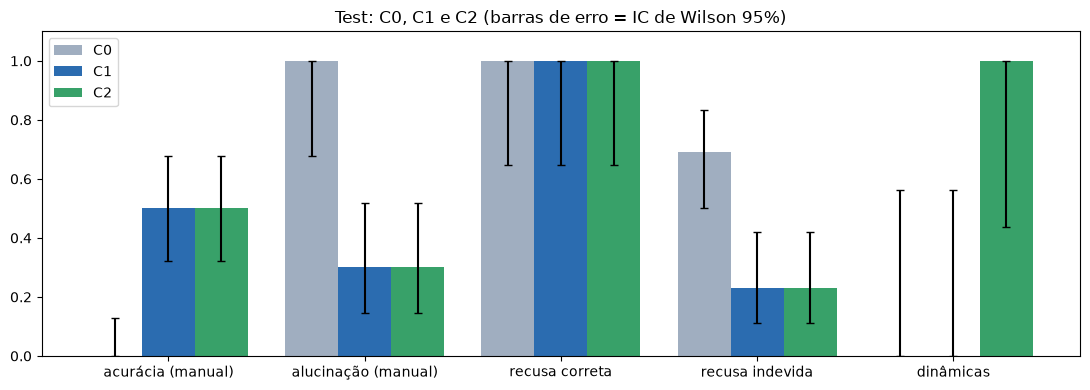

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
mets = [("acurácia manual (corretas)", "acurácia (manual)"),
        ("alucinação manual (respostas dadas que afirmam algo falso)", "alucinação (manual)"),
        ("recusa correta (não consta e fora do domínio)", "recusa correta"),
        ("recusa indevida (respondíveis)", "recusa indevida"),
        ("acerto nas dinâmicas (agenda)", "dinâmicas")]
cores = {"C0": "#a0aec0", "C1": "#2b6cb0", "C2": "#38a169"}
for i, cfg in enumerate(("C0", "C1", "C2")):
    sel = placar[(placar.split == "test") & (placar.config == cfg)].set_index("metrica")
    xs, ys, lo, hi = [], [], [], []
    for j, (m, _) in enumerate(mets):
        if m in sel.index:
            r = sel.loc[m]
            xs.append(j + (i - 1) * 0.27)
            ys.append(r["taxa"])
            lo.append(r["taxa"] - r["ic95_inf"])
            hi.append(r["ic95_sup"] - r["taxa"])
    ax.bar(xs, ys, width=0.27, color=cores[cfg], label=cfg, yerr=[lo, hi], capsize=3)
ax.set_xticks(range(len(mets)))
ax.set_xticklabels([rot for _, rot in mets])
ax.set_ylim(0, 1.1)
ax.set_title("Test: C0, C1 e C2 (barras de erro = IC de Wilson 95%)")
ax.legend()
plt.tight_layout()
plt.show()

## 2. Por tipo de pergunta (test, acurácia manual)

In [4]:
def vereditos(cfg):
    linhas, c2 = run(f"{cfg}_test_{Q}"), run(f"C2_test_{Q}")
    v = {}
    for id_, x in linhas.items():
        if x["tipo"] not in RESPONDIVEIS:
            continue
        r = x["saida"]["resposta"]
        if r["recusa"]:
            v[id_] = conf.get(f"{cfg}_recusas", {}).get(id_, {}).get("veredito", "recusa")
        elif id_ in conf.get(cfg, {}):
            v[id_] = conf[cfg][id_]["veredito"]
        else:
            v[id_] = conf["C2"][id_]["veredito"]  # C1 com resposta igual à do C2
    return v


linhas = []
for cfg in ("C0", "C1", "C2"):
    for id_, ver in vereditos(cfg).items():
        linhas.append({"config": cfg, "tipo": casos[id_].tipo, "veredito": ver})
pt = pd.DataFrame(linhas)
tab = pt.groupby(["tipo", "config"]).veredito.value_counts().unstack(fill_value=0)
tab["n"] = tab.sum(axis=1)
tab[[c for c in ("correta", "parcial", "incorreta", "recusa", "n") if c in tab.columns]]

veredito             correta  parcial  incorreta  recusa   n
tipo         config                                         
coloquial    C0            0        0          2       5   7
             C1            4        1          1       1   7
             C2            4        1          1       1   7
direta       C0            0        4          1       6  11
             C1            8        1          1       1  11
             C2            8        1          1       1  11
multi_trecho C0            0        1          0       3   4
             C1            1        1          1       1   4
             C2            1        1          1       1   4
ruido        C0            0        1          0       3   4
             C1            0        1          0       3   4
             C2            0        1          0       3   4

## 3. Métrica automática x conferência manual (C2, test)

A métrica automática procura os fatos-chave escritos como no gabarito, e a suspeita automática de
alucinação procura números fora dos trechos. A conferência mostra o limite das duas:
- **acurácia:** a automática reprova respostas certas escritas de outro jeito;
- **alucinação:** a automática não vê um número que existe num trecho, mas foi aplicado à
  situação errada.

In [5]:
c2 = run(f"C2_test_{Q}")
comp = []
for id_, x in c2.items():
    if x["tipo"] in RESPONDIVEIS and not x["saida"]["resposta"]["recusa"]:
        comp.append({"id": id_, "acurácia automática": x["metricas"]["acuracia"],
                     "veredito manual": conf["C2"][id_]["veredito"],
                     "suspeita automática": x["metricas"]["alucinacao"],
                     "afirma algo falso (manual)": conf["C2"][id_]["falso"]})
comp = pd.DataFrame(comp)
display(pd.crosstab(comp["acurácia automática"], comp["veredito manual"]))
pd.crosstab(comp["suspeita automática"], comp["afirma algo falso (manual)"])

veredito manual,correta,incorreta,parcial
acurácia automática,,,
False,4,3,4
True,9,0,0


afirma algo falso (manual),nao,sim
suspeita automática,,
False,14,6


## 4. Matriz de erros (taxonomia da seção 7.4)

,1. recuperação,2. fragmentação,3. recusa indevida,4. aceite indevido (não consta),5. número alterado,6. citação não sustenta,7. roteador/ferramenta,8. regra obsoleta,total
config,,,,,,,,,
C1,4,1,6,0,0,2,3,0,16
C2,4,1,6,0,0,2,0,0,13


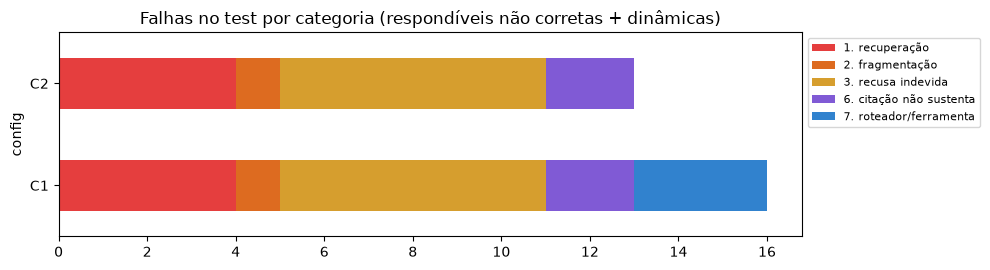

,veredito,categoria,secundaria,gold_no_top3,nota,evidencia
T-003,parcial,6,5,sim,0.7476,O item 196 tem quatro regras; o modelo aplicou a de unidades comerciais/industriais (3 dias úteis com cadastro) à residência comum (72 horas).
T-007,recusa,3,8,sim,0.6184,Veio o art. 621 sem o inciso VIII (revogado); o trecho da revogação (D06-art19) não veio. O LLM concluiu que faltava informação.
T-011,incorreta,1,6,nao,0.7085,"O critério geral (meio salário mínimo) não veio; veio o § 1º, critério excepcional de 3 salários mínimos, e o modelo o apresentou como regra geral."
T-021,parcial,1,5,nao,0.7215,"O art. 360 da REN 1.000 e a cláusula 6.3 do contrato de adesão (15 dias de aviso por inadimplemento) não vieram; com páginas do gov.br sobre corte, o modelo..."
T-024,recusa,3,1,nao,0.6017,Pergunta coloquial ('sou aposentado e recebo o BPC'); nota logo abaixo de τ e gold fora do top-3.
T-028,incorreta,6,None,sim,0.7021,O gold (adicional destacado na fatura) veio em 3º; o modelo seguiu a página do gov.br ('forma diferente de apresentar um custo que já estava na conta') e in...
T-032,recusa,3,None,sim,0.5895,"Voz com erros de grafia ('lus', 'quantu'). O gold veio em 1º, mas a nota ficou abaixo de τ: falha só do portão."
T-033,parcial,1,5,nao,0.6494,"Versão de voz da T-021; o art. 360 não veio e o modelo escreveu '5 dias úteis', número de outro trecho."
T-034,recusa,3,1,nao,0.5954,"Voz ('geladera', 'insolina', 'impresa'); nota abaixo de τ e gold fora do top-3."
T-036,recusa,3,1,nao,0.5426,"Versão de voz da T-024 ('aposentadu', 'disconto', 'lus'); nota bem abaixo de τ."


In [6]:
matriz = pd.read_csv(A / "matriz_erros.csv").set_index("config")
display(matriz)
cats = [c for c in matriz.columns if c != "total" and matriz[c].sum() > 0]
matriz[cats].plot(kind="barh", stacked=True, figsize=(10, 2.8),
                  color=["#e53e3e", "#dd6b20", "#d69e2e", "#805ad5", "#3182ce"][: len(cats)])
plt.title("Falhas no test por categoria (respondíveis não corretas + dinâmicas)")
plt.legend(fontsize=8, bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()
pd.DataFrame(erros).T[["veredito", "categoria", "secundaria", "gold_no_top3", "nota", "evidencia"]]

## 5. O portão de recusa (curva do limiar, Fase 4)

O τ foi escolhido no dev e na calibração: no máximo 5% das perguntas fora do domínio passam. No
test, o portão barrou corretamente 6 das 7 negativas; a outra foi recusada pelo LLM. Também
barrou 5 respondíveis, e em 2 delas (T-032, de voz, e T-040, multi-trecho) os trechos gold
estavam entre os 3 primeiros. As notas ficaram entre 0,59 e 0,60, logo abaixo do τ.

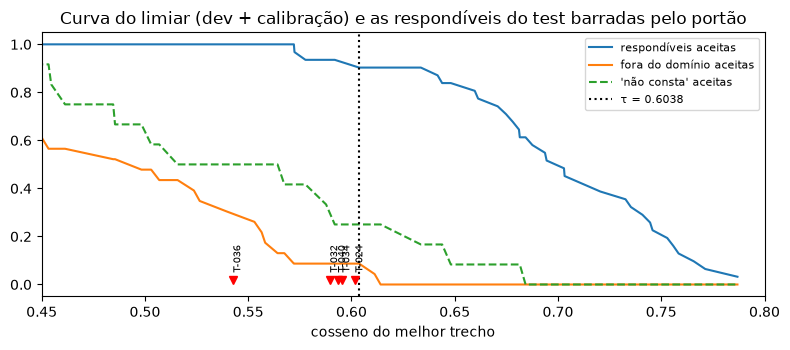

In [7]:
curva = pd.read_csv(A / "retrieval" / "limiar_curva.csv")
tau = json.loads((A / "retrieval" / "limiar.json").read_text(encoding="utf-8"))["tau"]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(curva.tau, curva.tpr, label="respondíveis aceitas")
ax.plot(curva.tau, curva.fpr, label="fora do domínio aceitas")
ax.plot(curva.tau, curva.nao_consta_aceitas, label="'não consta' aceitas", ls="--")
ax.axvline(tau, color="k", ls=":", label=f"τ = {tau}")
for id_, e in erros.items():
    if e["veredito"] == "recusa" and e["nota"] < tau:
        ax.plot(e["nota"], 0.02, "rv")
        ax.annotate(id_, (e["nota"], 0.06), fontsize=7, rotation=90)
ax.set_xlabel("cosseno do melhor trecho")
ax.set_xlim(0.45, 0.8)
ax.legend(fontsize=8)
ax.set_title("Curva do limiar (dev + calibração) e as respondíveis do test barradas pelo portão")
plt.tight_layout()
plt.show()

## 6. Interpretação

**O que a base de normas muda (C0 → C1).** Sem a base, o C0 não acerta nenhuma das 26
perguntas respondíveis. O erro mais comum dele não é inventar um número: **17 das 18 recusas
negam um direito que existe**. Exemplos: "não há desconto para quem recebe o BPC" e "não há
prazo para religar a luz". Nas 8 vezes em que respondeu, as 8 respostas afirmavam algo falso:
um prazo errado ou uma citação inventada de um artigo que não diz aquilo. Para um idoso, ouvir
que um direito não existe é tão grave quanto ouvir um prazo errado. Com a base, o C1 acerta
13/26 (17/26 contando as parciais), e toda resposta cita um trecho que pode ser conferido.

**O que o agente muda (C1 → C2).** Nas perguntas de normas, nada: o caminho é o mesmo, e a
acurácia manual empata em 13/26. Nas perguntas sobre a agenda de paradas, o C2 acerta 3/3, e o
C1 não tem como responder. O roteador acertou as 36 decisões do test.

**Onde ainda falha, e por quê** (13 falhas do C2):
- **O portão barra perguntas legítimas (6).** Voz com erros de grafia e perguntas coloquiais
  ficam com cosseno logo abaixo do τ, às vezes com o trecho certo na mão (T-032, T-040). Mais
  uma, a T-007, foi recusada pelo LLM com o trecho da regra em mãos.
- **A busca não traz o trecho certo, e o modelo responde com o mais parecido (4).** Esse é o
  erro mais perigoso: "três dias" e "5 dias úteis" em vez de 15 dias; "3 salários mínimos" em
  vez de meio salário mínimo. O número existe nos trechos, mas é de outra situação, então a
  verificação automática de números não detecta.
- **O modelo interpreta mal um trecho certo (2).** No T-028, a bandeira vermelha "não é cobrança
  a mais"; no T-003, o modelo trouxe a regra de outra classe de consumidor.
- **Fragmentação (1).** A resposta exigia dois trechos, e só um veio.

**Alucinação.** A taxa manual (6/20 respostas dadas, IC de 15% a 52%) é bem maior que a
automática (0/20). A automática sozinha passaria uma imagem otimista demais; a conferência
humana foi necessária.

**Comparação com as metas do plano:**
- **Atingidas:** JSON válido em 100%; recusa correta 7/7 (meta de 90%); latência p95 de 11,8 s
  no C2 (meta de 15 s).
- **Não atingidas:** recusa indevida de 6/26 = 23% (meta de no máximo 10%) e citação correta de
  12/20 = 60% (meta de 85%).

Os 5 erros detalhados e as correções estão no notebook 06.